# 🏠 House Price Regression Project

**End-to-end workflow:**

EDA → preprocessing → Pipeline → Linear Regression → evaluation → pickle export → import for futher use

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pickle
import json


In [2]:
df = pd.read_csv('house_data.csv')
df.head()


,area,bedrooms,bathrooms,age,price
0,800,1,1,25,2800000
1,950,2,1,20,3300000
2,1000,2,1,18,3500000
3,1100,2,1,15,3900000
4,1200,2,2,14,4300000


In [3]:
df.info()
df.describe()
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   area       61 non-null     int64
 1   bedrooms   61 non-null     int64
 2   bathrooms  61 non-null     int64
 3   age        61 non-null     int64
 4   price      61 non-null     int64
dtypes: int64(5)
memory usage: 2.5 KB


,0
area,0
bedrooms,0
bathrooms,0
age,0
price,0


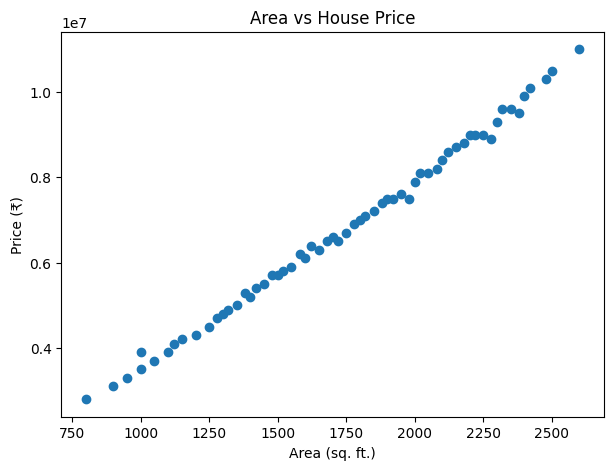

In [4]:
plt.figure(figsize=(7,5))
plt.scatter(df['area'], df['price'])
plt.xlabel('Area (sq. ft.)')
plt.ylabel('Price (₹)')
plt.title('Area vs House Price')
plt.show()


In [5]:
features = ['area', 'bedrooms', 'bathrooms', 'age']
X = df[features]
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)


In [6]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, features)
])

model_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', LinearRegression())
])

model_pipeline.fit(X_train, y_train)


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['area', 'bedrooms',
                                                   'bathrooms', 'age'])])),
                ('model', LinearRegression())])

In [7]:
y_pred = model_pipeline.predict(X_test)
mse = mean_squared_error(y_test, y_pred)

print('MAE :', mean_absolute_error(y_test, y_pred))
print('MSE :', mse)
print('RMSE:', mse ** 0.5)
print('R2  :', r2_score(y_test, y_pred))


MAE : 144215.78667912292
MSE : 33521661722.32116
RMSE: 183089.2179302789
R2  : 0.9931997397235892


In [8]:
with open('house_price_pipeline.pkl', 'wb') as file:
    pickle.dump(model_pipeline, file)

print('Pipeline exported successfully.')


Pipeline exported successfully.


In [9]:
sample = pd.DataFrame({
    'area': [1500],
    'bedrooms': [3],
    'bathrooms': [2],
    'age': [10]
})

print(f'Predicted Price: ₹{model_pipeline.predict(sample)[0]:,.0f}')


Predicted Price: ₹5,725,985


## Import the Pickle file (exported model)

In [10]:
my_model = None

with open('house_price_pipeline.pkl', 'rb') as file:
    my_model = pickle.load(file)

print('Model loaded successfully.')

my_model


Model loaded successfully.


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['area', 'bedrooms',
                                                   'bathrooms', 'age'])])),
                ('model', LinearRegression())])

In [11]:
input_data = pd.DataFrame(
        {
            "area": [2200],
            "bedrooms": [3],
            "bathrooms": [2],
            "age": [8],
        }
    )

In [17]:
print(f"Price is Rs. {my_model.predict(input_data)[0]:,.2f}")

Price is Rs. 8,907,726.24
